# Búsqueda en espacios continuos

Inteligencia Artificial - Facundo A. Lucianna - CEIA - FIUBA

Todos los problemas de búsqueda local que vimos hasta ahora tienen un espacio de estados discreto: una gira es una permutación de ciudades, y cada gira tiene una cantidad finita de vecinos, que podemos recorrer uno por uno. ¿Qué pasa si el estado es un punto del plano, o de un espacio de muchas dimensiones? Cada punto tiene infinitos vecinos, y la mayoría de los algoritmos que vimos dejan de funcionar tal como están, salvo que discreticemos el espacio.

Hay dos algoritmos que se adaptan muy bien a los espacios continuos:

- **Gradiente descendente**: en lugar de revisar todos los vecinos para encontrar el mejor, usamos el **gradiente** de la función, que nos dice directamente en qué dirección baja más rápido.
- **Simulated Annealing**: no necesita revisar todos los vecinos, solo generar uno al azar, y eso es fácil en un espacio continuo.

Para probarlos vamos a usar la [función de Himmelblau](https://en.wikipedia.org/wiki/Himmelblau%27s_function), muy usada para probar algoritmos de optimización:

$$f(x,y) = (x^2 + y - 11)^2 + (x + y^2 - 7)^2$$

Tiene cuatro mínimos, todos con valor cero, en los puntos `(3, 2)`, `(-2.805118, 3.131312)`, `(-3.779310, -3.283186)` y `(3.584428, -1.848126)`, y un máximo local en `(-0.270845, -0.923039)`.

In [1]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np

random.seed(42)
np.random.seed(42)


def himmelblau(x, y):
    return (x**2 + y - 11) ** 2 + (x + y**2 - 7) ** 2


HIMMELBLAU_MINIMA = np.array(
    [
        (3, 2),
        (-2.805118, 3.131312),
        (-3.779310, -3.283186),
        (3.584428, -1.848126),
    ]
)
HIMMELBLAU_MAXIMUM = (-0.270845, -0.923039)

Veamos la función con un mapa de contorno, donde cada curva une los puntos con el mismo valor. Los mínimos están marcados con una cruz roja y el máximo con un punto azul:

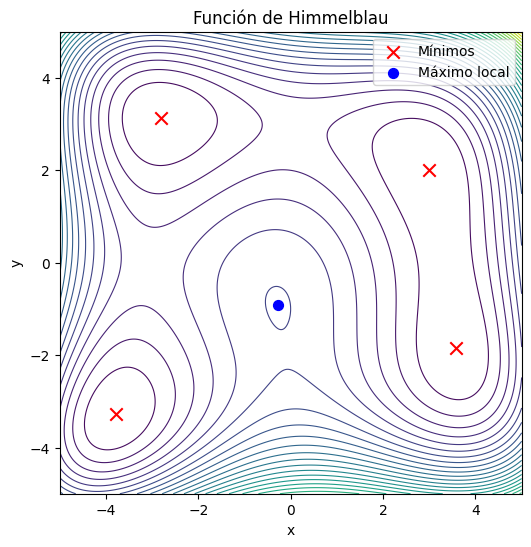

In [2]:
def plot_contour(function, limits, ax=None, filled=False):
    """
    Dibuja el mapa de contorno de una función de dos variables.

    Args:
        function (callable): La función, que recibe x e y.
        limits (tuple): Límites (mínimo, máximo) de los dos ejes.
        ax (plt.Axes, opcional): Dónde dibujar. Por defecto, en el gráfico actual.
        filled (bool, opcional): Si es True, pinta las regiones entre curvas en lugar
                                 de dibujar solo las curvas. Por defecto False.
    """
    ax = ax or plt.gca()
    grid = np.linspace(limits[0], limits[1], 400)
    xx, yy = np.meshgrid(grid, grid)
    if filled:
        ax.contourf(xx, yy, function(xx, yy), levels=20, cmap="viridis")
    else:
        ax.contour(xx, yy, function(xx, yy), levels=30, cmap="viridis", linewidths=0.8)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")


plt.figure(figsize=(6, 6))
plot_contour(himmelblau, (-5, 5))
plt.scatter(*HIMMELBLAU_MINIMA.T, color="red", marker="x", s=80, label="Mínimos")
plt.scatter(*HIMMELBLAU_MAXIMUM, color="blue", s=50, label="Máximo local")
plt.legend()
plt.title("Función de Himmelblau")
plt.show()

Y en tres dimensiones, donde se ven los cuatro pozos de los mínimos y la pequeña loma del máximo, en el medio:

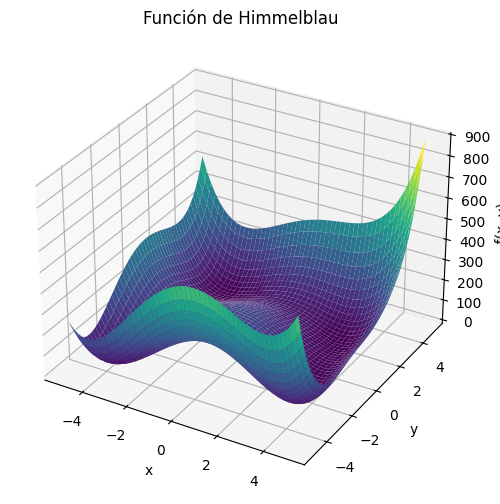

In [3]:
grid = np.linspace(-5, 5, 200)
X, Y = np.meshgrid(grid, grid)

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, Y, himmelblau(X, Y), cmap="viridis")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("f(x, y)")
ax.set_title("Función de Himmelblau")
plt.show()

---

## Gradiente descendente

El gradiente de una función es el vector de sus derivadas parciales, y apunta en la dirección en la que la función crece más rápido. Si nos movemos en la dirección contraria, bajamos lo más rápido posible.

Para la función de Himmelblau:

$$\nabla f = \left( \frac{\partial f}{\partial x}, \frac{\partial f}{\partial y} \right) = \left( 4x(x^2 + y - 11) + 2(x + y^2 - 7),\ 2(x^2 + y - 11) + 4y(x + y^2 - 7) \right)$$

In [4]:
def himmelblau_gradient(x, y):
    return (
        4 * x * (x**2 + y - 11) + 2 * (x + y**2 - 7),
        2 * (x**2 + y - 11) + 4 * y * (x + y**2 - 7),
    )

En cada paso, el algoritmo se mueve un poco en la dirección contraria al gradiente:

$$X_{nuevo} = X - \alpha \nabla f(X)$$

donde $\alpha$ es la **tasa de aprendizaje**, que define el tamaño del paso. Es la misma idea que en la gira: en cada paso nos movemos al vecino que más baja el costo. La diferencia es que acá no tenemos que revisar todos los vecinos para encontrarlo, porque el gradiente nos dice hacia dónde ir.

También cambia la condición para detenernos. En la gira nos deteníamos cuando ningún vecino mejoraba la gira actual. En un espacio continuo, en un mínimo el gradiente vale cero, pero por los errores numéricos nunca vale exactamente cero. Por eso nos detenemos cuando el módulo del gradiente es menor a una **tolerancia**:

In [5]:
def gradient_descent(
    gradient, start, learning_rate, max_iterations=10_000, tolerance=1e-6
):
    """
    Busca un mínimo con gradiente descendente.

    Args:
        gradient (callable): Función que recibe x e y y devuelve el gradiente.
        start (tuple): Punto desde donde arranca la búsqueda.
        learning_rate (float): Tasa de aprendizaje, el tamaño de cada paso.
        max_iterations (int, opcional): Cantidad máxima de pasos. Por defecto 10.000.
        tolerance (float, opcional): Se detiene cuando el módulo del gradiente es menor
                                     a este valor. Por defecto 1e-6.

    Returns:
        np.ndarray: El camino recorrido, un punto por fila. El último es el mínimo.
    """
    point = np.array(start, dtype=float)
    path = [point]

    for _ in range(max_iterations):
        step = np.array(gradient(*point))

        # Si el gradiente es casi cero, llegamos a un mínimo
        if np.linalg.norm(step) < tolerance:
            break

        # Nos movemos en la dirección contraria al gradiente
        point = point - learning_rate * step
        path.append(point)

    return np.array(path)

Arrancamos desde un punto cualquiera, con una tasa de aprendizaje de 0,005:

In [6]:
start = (-2.4, -2.4)
path = gradient_descent(himmelblau_gradient, start, learning_rate=0.005)

print(f"Mínimo encontrado: ({path[-1][0]:.6f}, {path[-1][1]:.6f})")
print(f"Valor de la función: {himmelblau(*path[-1]):.2e}")
print(f"Cantidad de pasos: {len(path) - 1}")

Mínimo encontrado: (-3.779310, -3.283186)
Valor de la función: 5.97e-15
Cantidad de pasos: 45


Veamos el camino que recorrió sobre el mapa de contorno:

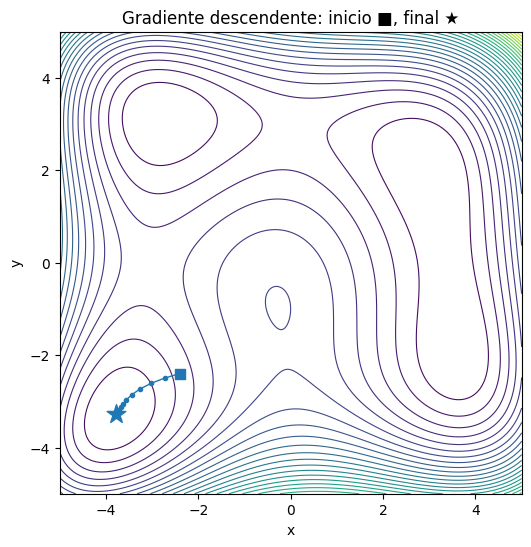

In [7]:
def plot_path(path, label=None, ax=None):
    """Dibuja el camino de una búsqueda, marcando el inicio y el final."""
    ax = ax or plt.gca()
    line = ax.plot(*path.T, "o-", markersize=3, linewidth=1, label=label)[0]
    ax.scatter(*path[0], color=line.get_color(), marker="s", s=60, zorder=3)
    ax.scatter(*path[-1], color=line.get_color(), marker="*", s=200, zorder=3)


plt.figure(figsize=(6, 6))
plot_contour(himmelblau, (-5, 5))
plot_path(path)
plt.title("Gradiente descendente: inicio ■, final ★")
plt.show()

Los primeros pasos son largos y los últimos muy cortos: el tamaño de cada paso es proporcional al gradiente, y el gradiente se achica a medida que nos acercamos al mínimo.

---

## La tasa de aprendizaje

La tasa de aprendizaje es el parámetro más importante del algoritmo. Si es muy chica, el algoritmo avanza lento y necesita muchos pasos. Si es muy grande, se pasa del mínimo, rebota de un lado al otro del pozo y puede no llegar nunca. Probemos tres valores desde el mismo punto:

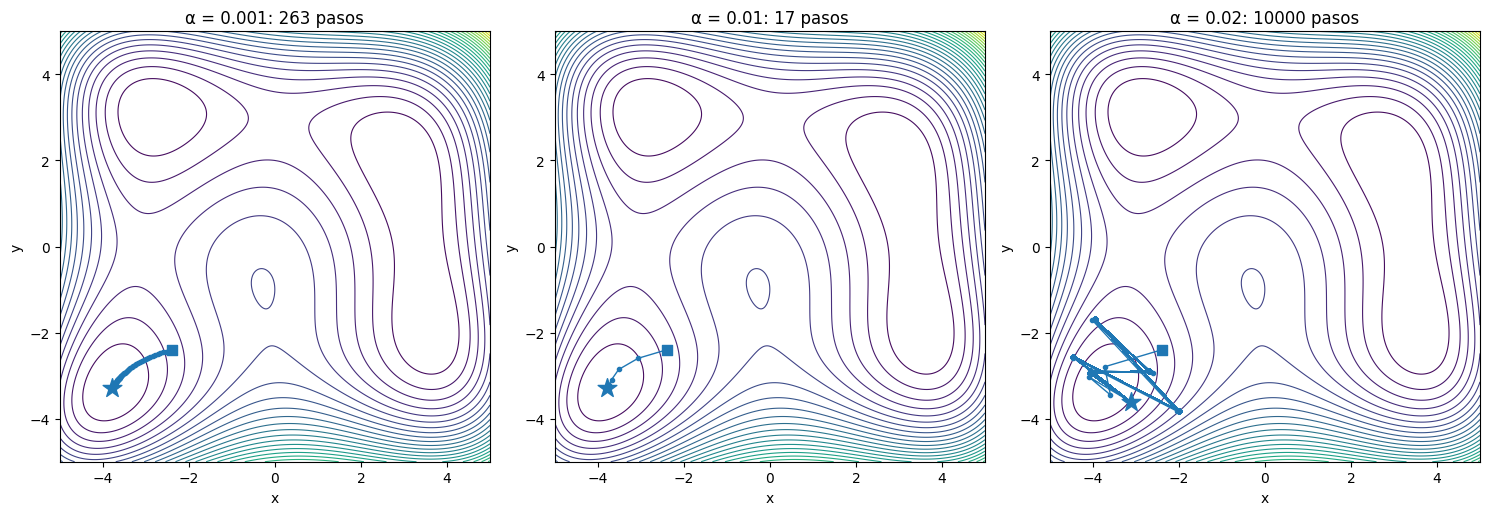

In [8]:
learning_rates = [0.001, 0.01, 0.02]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, learning_rate in zip(axes, learning_rates):
    path = gradient_descent(himmelblau_gradient, start, learning_rate)
    plot_contour(himmelblau, (-5, 5), ax=ax)
    plot_path(path, ax=ax)
    ax.set_title(f"α = {learning_rate}: {len(path) - 1} pasos")
plt.tight_layout()
plt.show()

Con α = 0,001 el algoritmo llega, pero en muchos más pasos. Con α = 0,01 llega en menos pasos que con 0,005. Con α = 0,02 los pasos son tan grandes que el algoritmo salta de un lado al otro del pozo sin llegar nunca al mínimo, hasta agotar las 10.000 iteraciones: la estrella marca dónde quedó al cortar, no un mínimo.

No hay una tasa de aprendizaje que sirva para todas las funciones: depende de qué tan empinada es la función. Por eso, en la práctica, se suelen usar variantes que la van ajustando durante la búsqueda, por ejemplo, empezar con pasos grandes e ir achicándolos.

---

## ¿A qué mínimo llegamos?

La función de Himmelblau tiene cuatro mínimos. ¿A cuál llega el algoritmo? Depende de dónde arranca, igual que en la gira dependía de la gira inicial. Para verlo, ejecutamos gradiente descendente desde una grilla de 200 x 200 puntos y pintamos cada punto de partida según el mínimo al que llegó.

En vez de llamar 40.000 veces a `gradient_descent()`, aprovechamos que numpy opera sobre arrays enteros y movemos todos los puntos a la vez:

In [9]:
grid = np.linspace(-5, 5, 200)
X, Y = np.meshgrid(grid, grid)

# Todos los puntos de la grilla dan 3.000 pasos de gradiente descendente a la vez
x, y = X.copy(), Y.copy()
for _ in range(3_000):
    gradient_x, gradient_y = himmelblau_gradient(x, y)
    x -= 0.005 * gradient_x
    y -= 0.005 * gradient_y

# Para cada punto, el índice del mínimo más cercano a donde terminó
distances = [np.hypot(x - mx, y - my) for mx, my in HIMMELBLAU_MINIMA]
reached = np.argmin(distances, axis=0)

# Consideramos que llegó si terminó a menos de una milésima del mínimo
ARRIVAL_TOLERANCE = 1e-3
lost = np.min(distances, axis=0) > ARRIVAL_TOLERANCE
print(f"Puntos que no llegaron a ningún mínimo: {lost.sum()}")

Puntos que no llegaron a ningún mínimo: 0


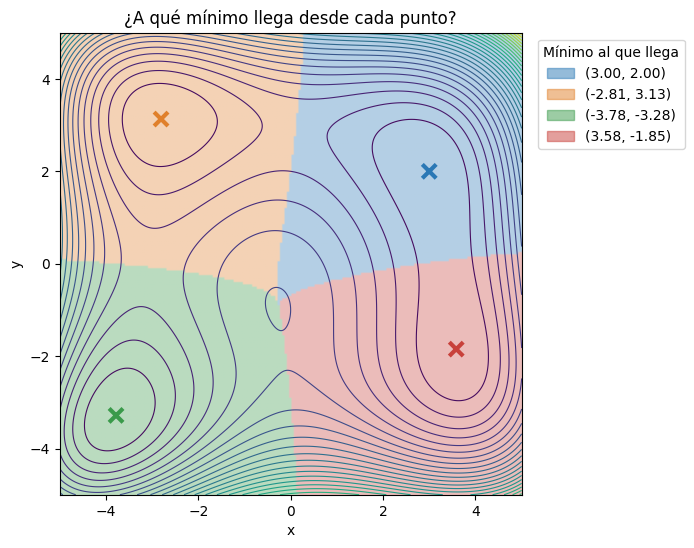

In [10]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

colors = ["#2a78b5", "#e0802b", "#3a9a4a", "#c8413b"]

plt.figure(figsize=(7, 6))
plt.imshow(
    reached,
    extent=(-5, 5, -5, 5),
    origin="lower",
    cmap=ListedColormap(colors),
    alpha=0.35,
)
plot_contour(himmelblau, (-5, 5))
plt.scatter(*HIMMELBLAU_MINIMA.T, c=colors, marker="x", s=100, linewidths=3)
plt.legend(
    handles=[
        Patch(color=color, alpha=0.5, label=f"({mx:.2f}, {my:.2f})")
        for color, (mx, my) in zip(colors, HIMMELBLAU_MINIMA)
    ],
    title="Mínimo al que llega",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
)
plt.title("¿A qué mínimo llega desde cada punto?")
plt.show()

Cada región de color es la **cuenca de atracción** de un mínimo: desde cualquier punto de esa región, gradiente descendente termina en ese mínimo. Las fronteras entre cuencas pasan por el máximo y por los puntos de ensilladura, y cerca de ellas un cambio muy chico en el punto de partida cambia el mínimo al que llegamos.

En la función de Himmelblau esto no es un problema, porque los cuatro mínimos valen lo mismo: lleguemos al que lleguemos, encontramos un mínimo global. Pero no siempre tenemos tanta suerte, como vamos a ver más adelante.

---

## Gradiente numérico

Hasta ahora calculamos el gradiente a mano, derivando la función. Muchas veces eso no es posible: la función puede ser muy complicada, o puede ser una simulación o un programa del que no conocemos la fórmula. En esos casos podemos **aproximar** las derivadas con **diferencias centrales**:

$$\frac{\partial f}{\partial x} \approx \frac{f(x + h, y) - f(x - h, y)}{2h}$$

donde $h$ es un número chico. Lo mismo para $y$:

In [11]:
def numerical_gradient(function, h=1e-5):
    """
    Devuelve una función que aproxima el gradiente de function con diferencias
    centrales.

    Args:
        function (callable): La función, que recibe x e y.
        h (float, opcional): El desplazamiento para aproximar las derivadas. Por
                             defecto 1e-5.

    Returns:
        callable: Función que recibe x e y y devuelve el gradiente aproximado.
    """

    def gradient(x, y):
        partial_x = (function(x + h, y) - function(x - h, y)) / (2 * h)
        partial_y = (function(x, y + h) - function(x, y - h)) / (2 * h)
        return partial_x, partial_y

    return gradient

Comparemos con el gradiente exacto en un punto cualquiera:

In [12]:
approximate_gradient = numerical_gradient(himmelblau)

print("Gradiente exacto:   ", himmelblau_gradient(1.0, 1.0))
print("Gradiente aproximado:", approximate_gradient(1.0, 1.0))

Gradiente exacto:    (-46.0, -38.0)
Gradiente aproximado: (-45.99999999896908, -37.99999999927195)


La aproximación es muy buena. Y como `gradient_descent()` recibe el gradiente como una función, podemos usarla sin cambiar nada:

In [13]:
path = gradient_descent(approximate_gradient, start, learning_rate=0.005)

print(f"Mínimo encontrado: ({path[-1][0]:.6f}, {path[-1][1]:.6f})")
print(f"Cantidad de pasos: {len(path) - 1}")

Mínimo encontrado: (-3.779310, -3.283186)
Cantidad de pasos: 45


Llega al mismo mínimo, en la misma cantidad de pasos. El costo es que cada paso evalúa la función cuatro veces: dos por cada variable. Con dos variables no es nada, pero con miles de variables, como en una red neuronal, cada paso necesitaría miles de evaluaciones. Por eso, cuando se puede, se calcula el gradiente exacto.

---

## Cuando hay mínimos locales: la función de Rastrigin

La [función de Rastrigin](https://en.wikipedia.org/wiki/Rastrigin_function) es todo lo contrario a la de Himmelblau. Es una parábola a la que se le suma un coseno, que la llena de pozos:

$$f(x,y) = 20 + x^2 - 10\cos(2\pi x) + y^2 - 10\cos(2\pi y)$$

Tiene un único mínimo global en `(0, 0)`, con valor cero, y un mínimo local cerca de cada punto con coordenadas enteras.

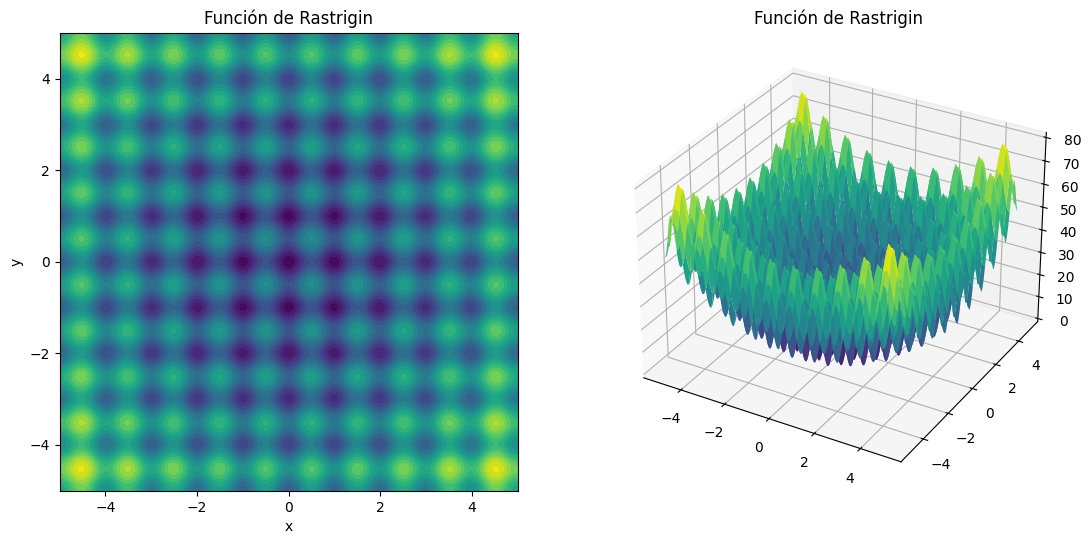

In [14]:
def rastrigin(x, y):
    return 20 + x**2 - 10 * np.cos(2 * np.pi * x) + y**2 - 10 * np.cos(2 * np.pi * y)


def rastrigin_gradient(x, y):
    return (
        2 * x + 20 * np.pi * np.sin(2 * np.pi * x),
        2 * y + 20 * np.pi * np.sin(2 * np.pi * y),
    )


fig = plt.figure(figsize=(13, 6))
ax = fig.add_subplot(1, 2, 1)
plot_contour(rastrigin, (-5, 5), ax=ax, filled=True)
ax.set_title("Función de Rastrigin")

ax = fig.add_subplot(1, 2, 2, projection="3d")
X, Y = np.meshgrid(grid, grid)
ax.plot_surface(X, Y, rastrigin(X, Y), cmap="viridis")
ax.set_title("Función de Rastrigin")
plt.show()

Ejecutemos gradiente descendente desde 20 puntos al azar. Como la función es mucho más empinada que la de Himmelblau, usamos una tasa de aprendizaje más chica:

In [15]:
starts = np.random.uniform(-5, 5, size=(20, 2))

gradient_ends = []
for point in starts:
    path = gradient_descent(rastrigin_gradient, point, learning_rate=0.001)
    gradient_ends.append(path[-1])
gradient_ends = np.array(gradient_ends)

gradient_values = sorted(rastrigin(*end) for end in gradient_ends)
print("Valor de la función en los 20 puntos encontrados:")
print(np.round(gradient_values, 2))

Valor de la función en los 20 puntos encontrados:
[ 3.98  4.97  4.97  4.97  4.97  4.97  8.95  8.95  9.95 16.91 16.91 17.91
 17.91 17.91 19.9  25.87 31.84 31.84 33.83 49.75]


Ninguna de las 20 ejecuciones encuentra el mínimo global. Cada una cae en el pozo más cercano a donde arrancó y se queda ahí, igual que gradiente descendente en la gira se quedaba en el primer mínimo local que encontraba.

---

## Simulated Annealing en un espacio continuo

Simulated Annealing no necesita el gradiente. En la gira, en cada paso generaba un vecino al azar con un movimiento 2-opt. Acá, el vecino es el punto actual más un pequeño desplazamiento al azar, que sacamos de una distribución normal. El resto del algoritmo es igual: si el vecino es mejor nos movemos, y si es peor nos movemos con probabilidad $e^{-\Delta/T}$, con una temperatura que va bajando.

In [16]:
# Desvío estándar del desplazamiento al azar con el que se genera cada vecino
STEP_SIZE = 0.5


def simulated_annealing(
    function,
    start,
    initial_temperature=10,
    final_temperature=0.01,
    max_iterations=20_000,
):
    """
    Busca un mínimo con Simulated Annealing. El vecino de un punto es el mismo punto
    más un desplazamiento al azar, con distribución normal de desvío STEP_SIZE.

    Args:
        function (callable): La función a minimizar, que recibe x e y.
        start (tuple): Punto desde donde arranca la búsqueda.
        initial_temperature (float, opcional): Temperatura inicial. Por defecto 10.
        final_temperature (float, opcional): Temperatura en la última iteración. Por
                                             defecto 0,01.
        max_iterations (int, opcional): Cantidad de iteraciones. Por defecto 20.000.

    Returns:
        np.ndarray: El mejor punto encontrado.
    """
    point = np.array(start, dtype=float)
    value = function(*point)
    best_point, best_value = point, value

    # Enfriamiento geométrico, igual que en la gira
    cooling_rate = (final_temperature / initial_temperature) ** (1 / max_iterations)
    temperature = initial_temperature

    for _ in range(max_iterations):
        # El vecino: un pequeño desplazamiento al azar
        neighbor = point + np.random.normal(0, STEP_SIZE, size=2)
        delta = function(*neighbor) - value

        if delta < 0 or random.random() < math.exp(-delta / temperature):
            point, value = neighbor, value + delta
            if value < best_value:
                best_point, best_value = point, value

        temperature *= cooling_rate

    return best_point

Lo ejecutamos desde los mismos 20 puntos de partida:

In [17]:
annealing_ends = np.array([simulated_annealing(rastrigin, point) for point in starts])

annealing_values = sorted(rastrigin(*end) for end in annealing_ends)
print("Valor de la función en los 20 puntos encontrados:")
print(np.round(annealing_values, 3))

Valor de la función en los 20 puntos encontrados:
[0.    0.    0.    0.001 0.001 0.001 0.002 0.003 0.003 0.004 0.004 0.005
 0.006 0.007 0.009 0.009 0.015 0.017 0.02  0.044]


Todas las ejecuciones terminan cerca del mínimo global. Veamos dónde terminó cada algoritmo:

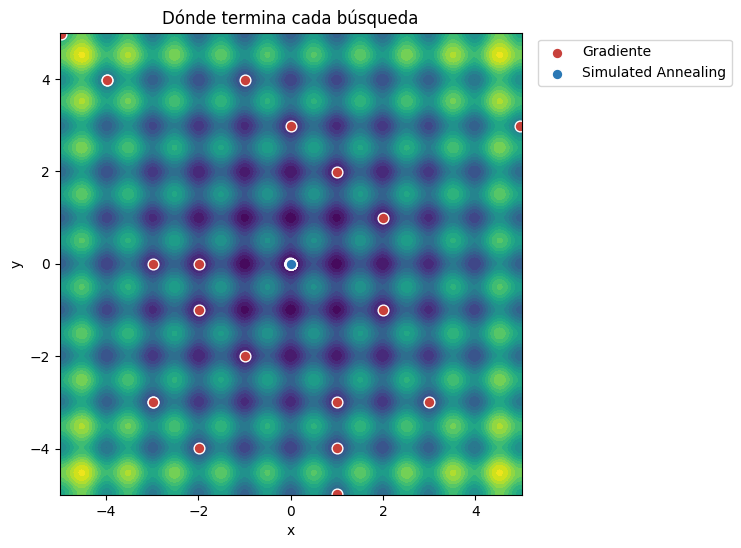

In [18]:
plt.figure(figsize=(7, 6))
plot_contour(rastrigin, (-5, 5), filled=True)
plt.scatter(
    *gradient_ends.T, color="#c8413b", edgecolor="white", s=60, label="Gradiente"
)
plt.scatter(
    *annealing_ends.T,
    color="#2a78b5",
    edgecolor="white",
    s=60,
    label="Simulated Annealing",
)
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.title("Dónde termina cada búsqueda")
plt.show()

Gradiente descendente queda desparramado por todo el mapa, cada ejecución en un pozo distinto. Los 20 puntos de Simulated Annealing, en cambio, están todos encimados en el centro. Mientras la temperatura es alta, Simulated Annealing salta de pozo en pozo, y a medida que se enfría se va quedando en los pozos más bajos, hasta terminar en el del centro.

Lo que no tiene Simulated Annealing es precisión: como se mueve con pasos al azar, termina cerca del mínimo, pero no exactamente en él. Para eso, gradiente descendente es mucho mejor. Así que podemos combinarlos: Simulated Annealing encuentra el pozo correcto y gradiente descendente baja hasta el fondo, la misma idea que el algoritmo memético de la gira:

In [19]:
worst = max(annealing_ends, key=lambda end: rastrigin(*end))
path = gradient_descent(rastrigin_gradient, worst, learning_rate=0.001)

refined = path[-1]

print(f"Simulated Annealing:  ({worst[0]:.4f}, {worst[1]:.4f})")
print(f"    f = {rastrigin(*worst):.4f}")
print(f"Después de gradiente: ({refined[0]:.4f}, {refined[1]:.4f})")
print(f"    f = {rastrigin(*refined):.2e}")

Simulated Annealing:  (-0.0129, -0.0075)
    f = 0.0438
Después de gradiente: (-0.0000, -0.0000)
    f = 1.78e-15


Partiendo de la peor ejecución de Simulated Annealing, gradiente descendente llega al mínimo global en unos pocos pasos.

En resumen, en los espacios continuos se repiten las mismas lecciones que en la gira: gradiente descendente es rápido y preciso, pero se queda en el mínimo local más cercano al punto de partida, y Simulated Annealing escapa de los mínimos locales a cambio de más evaluaciones de la función. La novedad es el gradiente, que nos ahorra revisar los vecinos y que, cuando no lo podemos calcular, podemos aproximar.